# Rice Leaf Disease Detection Using CNN
## Complete Data Analysis, CNN Modeling, and Data Augmentation Report
**Objective:** analyze the extracted rice-leaf image dataset, train CNN classifiers, compare augmentation with a baseline, and report measured results.

The archive audit previously found 119 readable images (39 Leaf smut, 40 Brown spot, 40 Bacterial leaf blight), rather than the stated 120. The code below re-counts the images in your own extracted folder; use the current notebook output as the source of truth.

The dataset is very small. Metrics may vary substantially by split, so treat this as an educational prototype rather than a field-validated disease diagnostic system.

## 1. Import libraries
Load tools for image handling, data analysis, CNN training, visualization, and evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
import random

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


## 2. Load the extracted dataset
Set `DATA_DIR` to the folder that directly contains the three class folders (or their parent folder). The code searches subfolders recursively and uses each image's parent folder as its class label. If the ZIP extracted an extra parent folder, update `DATA_DIR` accordingly.

In [2]:
data_path = Path("Data")

class_names = [
    "Bacterial leaf blight",
    "Brown spot",
    "Leaf smut"
]

image_extensions = {".jpg", ".jpeg", ".png"}

image_paths = []
labels = []

for class_name in class_names:
    class_folder = data_path / class_name

    for image_path in class_folder.iterdir():
        if image_path.is_file() and image_path.suffix.lower() in image_extensions:
            image_paths.append(str(image_path))
            labels.append(class_name)

df = pd.DataFrame({
    "Image_Path": image_paths,
    "Disease": labels
})

print("Total images:", len(df))
print("\nImages per class:")
print(df["Disease"].value_counts())

print("\nDataset preview:")
print(df.head())

Total images: 119

Images per class:
Disease
Bacterial leaf blight    40
Brown spot               40
Leaf smut                39
Name: count, dtype: int64

Dataset preview:
                                Image_Path                Disease
0  Data\Bacterial leaf blight\DSC_0365.JPG  Bacterial leaf blight
1  Data\Bacterial leaf blight\DSC_0366.jpg  Bacterial leaf blight
2  Data\Bacterial leaf blight\DSC_0367.JPG  Bacterial leaf blight
3  Data\Bacterial leaf blight\DSC_0370.jpg  Bacterial leaf blight
4  Data\Bacterial leaf blight\DSC_0372.JPG  Bacterial leaf blight


## 3. Initial data inspection
Check the number of records and column types.

In [3]:
print("Dataset shape:", df.shape)
print("\nColumn information:")
print(df.info())

Dataset shape: (119, 2)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Image_Path  119 non-null    object
 1   Disease     119 non-null    object
dtypes: object(2)
memory usage: 2.0+ KB
None


### 3.1 Missing-value check
Image paths and class names are generated from files, so missing values are not expected; this check confirms that.

In [4]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
Image_Path    0
Disease       0
dtype: int64


### 3.2 Duplicate path check
This detects repeated path strings only, not duplicate image content. If needed, a future improvement is to compare image hashes to detect identical files.

In [5]:
print("\nDuplicate image paths:", df["Image_Path"].duplicated().sum())


Duplicate image paths: 0


### 3.3 Number of classes
Expected classes are Leaf smut, Brown spot, and Bacterial leaf blight. Confirm that the folder names match these labels; folder names are used as the target labels.

In [6]:
print("\nNumber of disease classes:", df["Disease"].nunique())
print("\nClass names:")
print(df["Disease"].unique())


Number of disease classes: 3

Class names:
['Bacterial leaf blight' 'Brown spot' 'Leaf smut']


### 3.4 Class distribution
A bar chart shows how many images belong to each class. The project description expects 40 images per class. Balanced counts do not guarantee balanced model performance.

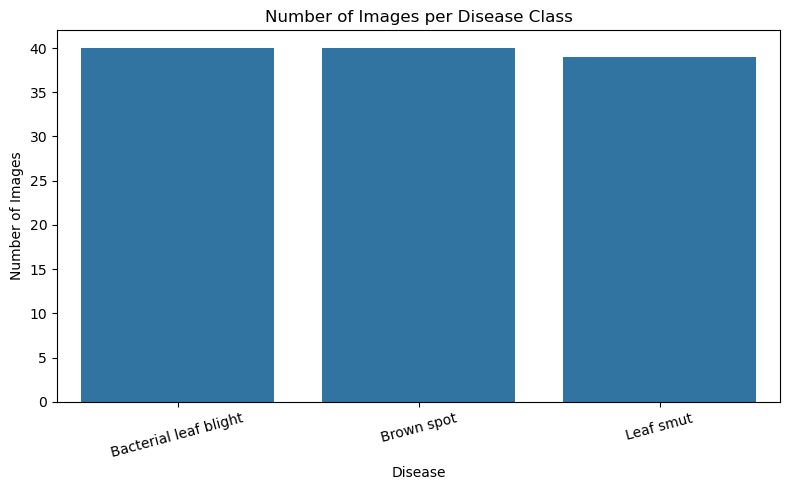

In [7]:
class_counts = df["Disease"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("Number of Images per Disease Class")
plt.xlabel("Disease")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 3.5 Sample image visualization
Visual inspection helps identify visible symptoms and check whether the folder labels appear plausible. A visual sample alone is not sufficient to validate labels.

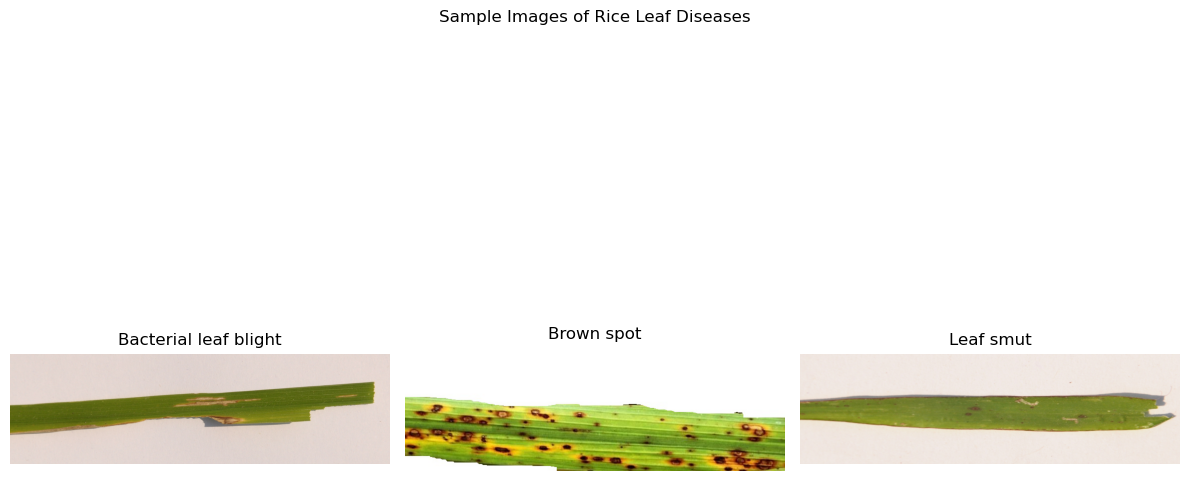

In [8]:
plt.figure(figsize=(12, 8))

shown = 0
for disease in sorted(df["Disease"].unique()):
    sample_paths = df.loc[df["Disease"] == disease, "Image_Path"]

    sample_image = None
    for sample_path in sample_paths:
        try:
            with Image.open(sample_path) as img:
                sample_image = img.convert("RGB")
            break
        except Exception:
            continue

    if sample_image is not None:
        shown += 1
        plt.subplot(1, len(df["Disease"].unique()), shown)
        plt.imshow(sample_image)
        plt.title(disease)
        plt.axis("off")

if shown == 0:
    print("No readable sample images were found.")
else:
    plt.suptitle("Sample Images of Rice Leaf Diseases")
    plt.tight_layout()
    plt.show()

### 3.6 Image quality and dimensions
Inspect width, height, format, and color mode. Unreadable images are reported. The preprocessing step keeps only images that could be opened successfully.

In [9]:
image_info = []

for path in df["Image_Path"]:
    try:
        with Image.open(path) as img:
            image_info.append({
                "Image_Path": path,
                "Width": img.width,
                "Height": img.height,
                "Format": img.format,
                "Mode": img.mode
            })
    except Exception as e:
        print("Unreadable image:", path, e)

image_info_df = pd.DataFrame(image_info)

print(image_info_df.head())
print("\nImage dimension summary:")
print(image_info_df[["Width", "Height"]].describe())
print("\nImage formats:")
print(image_info_df["Format"].value_counts())

                                Image_Path  Width  Height Format Mode
0  Data\Bacterial leaf blight\DSC_0365.JPG   3081     897   JPEG  RGB
1  Data\Bacterial leaf blight\DSC_0366.jpg   3081     897   JPEG  RGB
2  Data\Bacterial leaf blight\DSC_0367.JPG   3081     897   JPEG  RGB
3  Data\Bacterial leaf blight\DSC_0370.jpg   3081     897   JPEG  RGB
4  Data\Bacterial leaf blight\DSC_0372.JPG   3081     897   JPEG  RGB

Image dimension summary:
             Width      Height
count   119.000000  119.000000
mean   2383.638655  707.739496
std    1123.528972  311.657582
min     250.000000   71.000000
25%    1074.000000  377.000000
50%    3081.000000  897.000000
75%    3081.000000  897.000000
max    3081.000000  900.000000

Image formats:
Format
JPEG    119
Name: count, dtype: int64


## 3.7 Image integrity and duplicate-content audit

Duplicate paths are not the same as duplicate image contents. This check calculates SHA-256 hashes of the original image files to flag exact byte-identical files. It does not detect visually similar images saved with different compression or metadata.

In [10]:
import hashlib

def sha256_file(file_path):
    digest = hashlib.sha256()
    with open(file_path, 'rb') as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

if not df.empty:
    df['SHA256'] = df['Image_Path'].apply(sha256_file)
    duplicate_content = df[df.duplicated('SHA256', keep=False)].sort_values('SHA256')
    print('Exact byte-identical duplicate files:', int(df['SHA256'].duplicated().sum()))
    if duplicate_content.empty:
        print('No exact duplicate file contents detected.')
    else:
        display(duplicate_content[['Image_Path', 'Disease', 'SHA256']])
else:
    print('No images available for duplicate-content audit.')

Exact byte-identical duplicate files: 0
No exact duplicate file contents detected.


## 3.8 Image dimensions by disease class

This analysis checks whether image width and height vary across disease folders. Differences in image dimensions can reflect capture or dataset preparation differences; they should not automatically be interpreted as disease characteristics.

Image dimensions by class:


Width                     Height                 
                      count   min  median   max  count  min median  max
Disease                                                                
Bacterial leaf blight    40  3081  3081.0  3081     40  897  897.0  897
Brown spot               40   286  3081.0  3081     40   88  897.0  900
Leaf smut                39   250  3081.0  3081     39   71  897.0  897

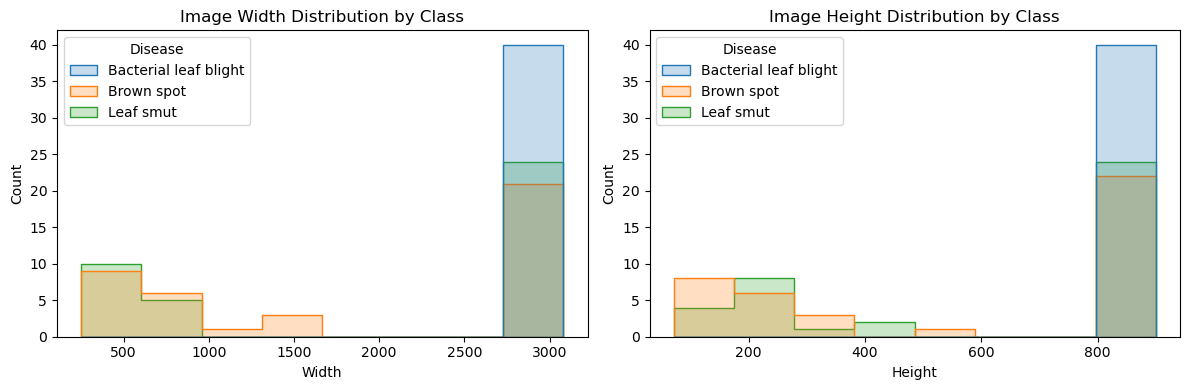

In [11]:
image_analysis = df.merge(image_info_df, on='Image_Path', how='left', validate='one_to_one')

print('Image dimensions by class:')
display(image_analysis.groupby('Disease')[['Width', 'Height']].agg(['count', 'min', 'median', 'max']).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=image_analysis, x='Width', hue='Disease', element='step', stat='count', common_norm=False, ax=axes[0])
axes[0].set_title('Image Width Distribution by Class')
sns.histplot(data=image_analysis, x='Height', hue='Disease', element='step', stat='count', common_norm=False, ax=axes[1])
axes[1].set_title('Image Height Distribution by Class')
plt.tight_layout()
plt.show()

## 3.9 EDA Findings and Interpretation

The dataset contains 119 readable images:
- Bacterial leaf blight: 40 images
- Brown spot: 40 images
- Leaf smut: 39 images

The classes are nearly balanced. Images have different dimensions, so all images are resized to 128 × 128 pixels before CNN training.

The assignment mentions Leaf blast, but the dataset contains Leaf smut. This difference must be confirmed with the instructor.

In [12]:
print('EDA summary')
print('Total image paths initially found:', len(image_paths))
print('Readable images:', len(image_info_df))
print('Unreadable images:', len(image_paths) - len(image_info_df))
print('Disease classes:', sorted(df['Disease'].unique()))
print('Class counts:')
display(df['Disease'].value_counts().rename_axis('Disease').to_frame('Image_Count'))
if 'SHA256' in df.columns:
    print('Files participating in exact duplicate groups:', int(df.duplicated('SHA256', keep=False).sum()))

EDA summary
Total image paths initially found: 119
Readable images: 119
Unreadable images: 0
Disease classes: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']
Class counts:


,Image_Count
Disease,
Bacterial leaf blight,40
Brown spot,40
Leaf smut,39


Files participating in exact duplicate groups: 0


## 4. Image preprocessing
Images are resized to 128 × 128 pixels, converted to RGB, and normalized to [0, 1]. Labels are encoded as integers, which works with sparse categorical cross-entropy.

In [13]:
IMG_SIZE = (128, 128)

# Keep only images that could be opened successfully
valid_paths = set(image_info_df["Image_Path"])
df = df[df["Image_Path"].isin(valid_paths)].copy()
df = df.reset_index(drop=True)

X = []
y = []

class_names = sorted(df["Disease"].unique())
class_to_index = {name: i for i, name in enumerate(class_names)}

for _, row in df.iterrows():
    image = Image.open(row["Image_Path"]).convert("RGB")
    image = image.resize(IMG_SIZE)

    X.append(np.array(image, dtype=np.float32) / 255.0)
    y.append(class_to_index[row["Disease"]])

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int32)

print("Image array shape:", X.shape)
print("Label array shape:", y.shape)
print("Classes:", class_names)

Image array shape: (119, 128, 128, 3)
Label array shape: (119,)
Classes: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']


### 4.1 Preview preprocessed images
Confirm that images still look sensible after resizing and normalization.

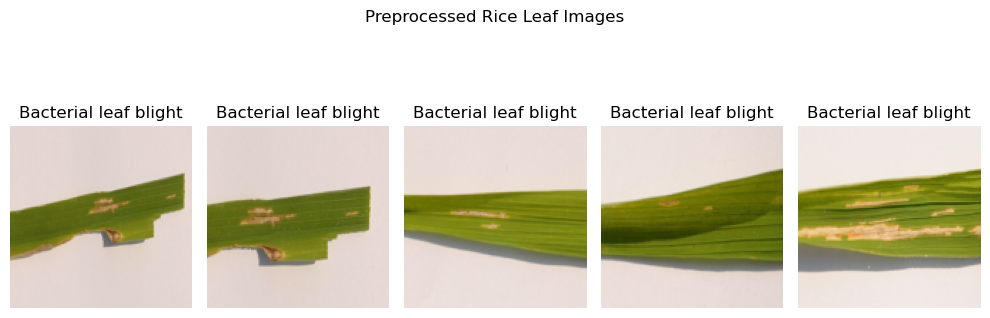

In [14]:
plt.figure(figsize=(10, 4))

for i in range(min(5, len(X))):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X[i])
    plt.title(class_names[y[i]])
    plt.axis("off")

plt.suptitle("Preprocessed Rice Leaf Images")
plt.tight_layout()
plt.show()

## 5. Train, validation, and test split
Use stratified sampling to preserve class proportions: approximately 70% training, 15% validation, and 15% testing. The validation set is used for model selection; the test set is reserved for final evaluation.

In [15]:
print("Total images:", len(X))
print("\nImages in each class:")
print(pd.Series(y).value_counts())

Total images: 119

Images in each class:
0    40
1    40
2    39
Name: count, dtype: int64


In [16]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

Training images: 83
Validation images: 18
Testing images: 18


In [17]:
split_summary = pd.DataFrame({
    'Train': pd.Series(y_train).value_counts().reindex(range(len(class_names)), fill_value=0),
    'Validation': pd.Series(y_val).value_counts().reindex(range(len(class_names)), fill_value=0),
    'Test': pd.Series(y_test).value_counts().reindex(range(len(class_names)), fill_value=0)
})
split_summary.index = class_names
print('Class counts in each split:')
display(split_summary)

# This confirms that each class is represented in every subset.

Class counts in each split:


,Train,Validation,Test
Bacterial leaf blight,28,6,6
Brown spot,28,6,6
Leaf smut,27,6,6


## 6. Define the CNN architecture
The network uses convolution and pooling layers to learn visual patterns, followed by a dense layer and softmax output for three-class prediction. The augmentation layers are included only when `use_augmentation=True`.

In [18]:
def build_cnn(use_augmentation=False):

    model = models.Sequential()

    model.add(layers.Input(shape=(128, 128, 3)))

    if use_augmentation:
        model.add(layers.RandomFlip("horizontal"))
        model.add(layers.RandomRotation(0.08))
        model.add(layers.RandomZoom(0.10))

    model.add(layers.Conv2D(32, (3, 3), activation="relu"))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Conv2D(64, (3, 3), activation="relu"))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Conv2D(128, (3, 3), activation="relu"))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation="relu"))
    model.add(layers.Dropout(0.40))
    model.add(layers.Dense(len(class_names), activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

### 6.1 Visual check of augmentation

The transformations are applied dynamically during training and do not create permanent extra files. Review examples to ensure that the transformed images still preserve meaningful leaf-disease patterns.

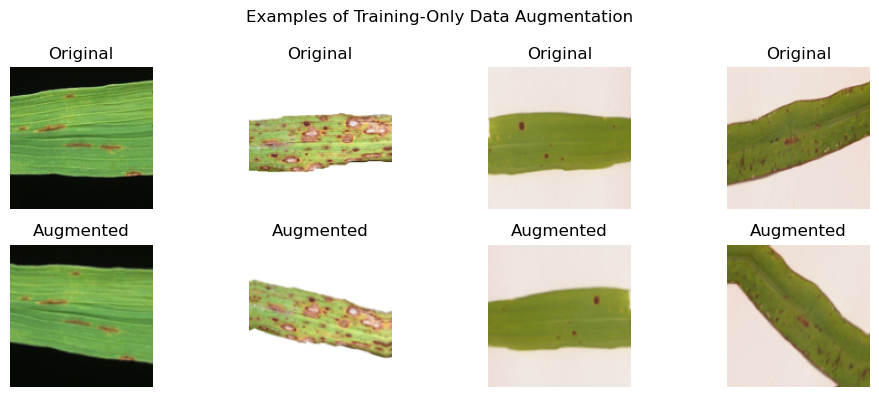

In [19]:
augmentation_preview = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10)
])

plt.figure(figsize=(10, 4))
for i in range(min(4, len(X_train))):
    augmented_image = augmentation_preview(tf.expand_dims(X_train[i], axis=0), training=True)[0].numpy()
    plt.subplot(2, 4, i + 1)
    plt.imshow(X_train[i])
    plt.title('Original')
    plt.axis('off')
    plt.subplot(2, 4, i + 5)
    plt.imshow(np.clip(augmented_image, 0, 1))
    plt.title('Augmented')
    plt.axis('off')
plt.suptitle('Examples of Training-Only Data Augmentation')
plt.tight_layout()
plt.show()

### 6.1 CNN 1 — without augmentation
This is the baseline CNN trained on the original training images.

In [20]:
tf.keras.utils.set_random_seed(42)

cnn_basic = build_cnn(use_augmentation=False)

cnn_basic.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

### 6.2 Train CNN 1
Early stopping monitors validation loss and restores weights from the best validation-loss epoch.

In [21]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_basic = cnn_basic.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=8,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 218ms/step - accuracy: 0.3253 - loss: 1.1811 - val_accuracy: 0.4444 - val_loss: 1.0702
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 179ms/step - accuracy: 0.4699 - loss: 1.0547 - val_accuracy: 0.6667 - val_loss: 0.9289
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 181ms/step - accuracy: 0.6747 - loss: 0.8845 - val_accuracy: 0.7778 - val_loss: 0.7217
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 172ms/step - accuracy: 0.6988 - loss: 0.7073 - val_accuracy: 0.6667 - val_loss: 0.6856
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 171ms/step - accuracy: 0.6747 - loss: 0.6304 - val_accuracy: 0.6667 - val_loss: 0.7174
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 176ms/step - accuracy: 0.8313 - loss: 0.4085 - val_accuracy: 0.6111 - val_loss: 1.0122
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 171ms/step - accuracy: 0.9036 - loss: 0.2850 - val_accuracy: 0.6667 - val_loss: 1.0331
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 171ms/step - accuracy: 0.9277 - loss: 0.1840 - val_accuracy: 0.

### 6.3 Training curves for CNN 1
A growing gap between training and validation performance can indicate overfitting.

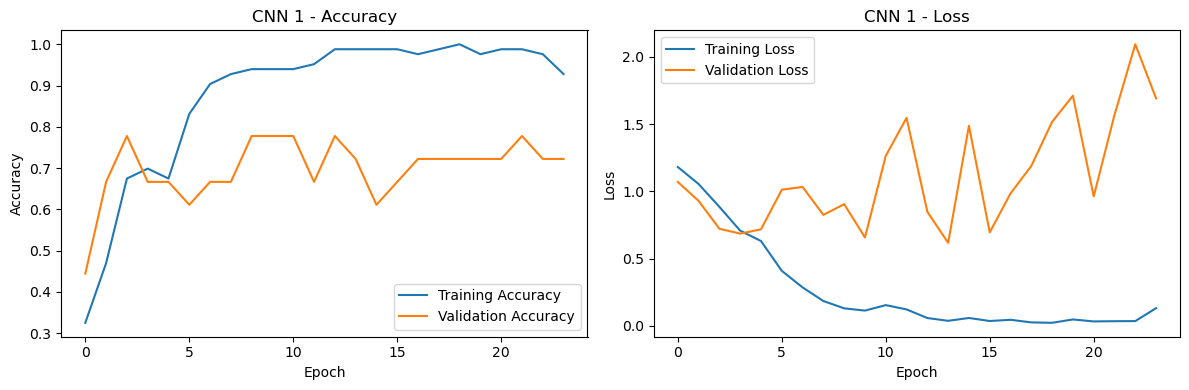

In [22]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_basic.history["accuracy"], label="Training Accuracy")
plt.plot(history_basic.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN 1 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_basic.history["loss"], label="Training Loss")
plt.plot(history_basic.history["val_loss"], label="Validation Loss")
plt.title("CNN 1 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 7. CNN 2 — with data augmentation
Horizontal flipping, small rotations, and zoom transformations are applied dynamically to training images. They do not create permanent new files and are inactive during inference.

In [23]:
tf.keras.utils.set_random_seed(42)

cnn_augmented = build_cnn(use_augmentation=True)

cnn_augmented.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)           │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation_1 (RandomRotation)   │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_zoom_1 (RandomZoom)           │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

### 7.1 Train CNN 2
The architecture and training settings are kept similar so the main experimental difference is augmentation.

In [24]:
history_augmented = cnn_augmented.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=8,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 232ms/step - accuracy: 0.3012 - loss: 1.2338 - val_accuracy: 0.3333 - val_loss: 1.0901
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 181ms/step - accuracy: 0.3614 - loss: 1.1033 - val_accuracy: 0.6111 - val_loss: 1.0869
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 183ms/step - accuracy: 0.3976 - loss: 1.0914 - val_accuracy: 0.5556 - val_loss: 1.0431
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 189ms/step - accuracy: 0.5663 - loss: 1.0206 - val_accuracy: 0.5556 - val_loss: 0.8166
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 181ms/step - accuracy: 0.5060 - loss: 0.9650 - val_accuracy: 0.5556 - val_loss: 0.8706
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 186ms/step - accuracy: 0.6145 - loss: 0.9015 - val_accuracy: 0.5556 - val_loss: 0.8140
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 188ms/step - accuracy: 0.5783 - loss: 0.9155 - val_accuracy: 0.6111 - val_loss: 0.7394
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 182ms/step - accuracy: 0.6627 - loss: 0.8367 - val_accuracy: 0.

### 7.2 Training curves for CNN 2
Compare training and validation curves with the baseline. Augmentation may improve generalization, but improvement is not guaranteed.

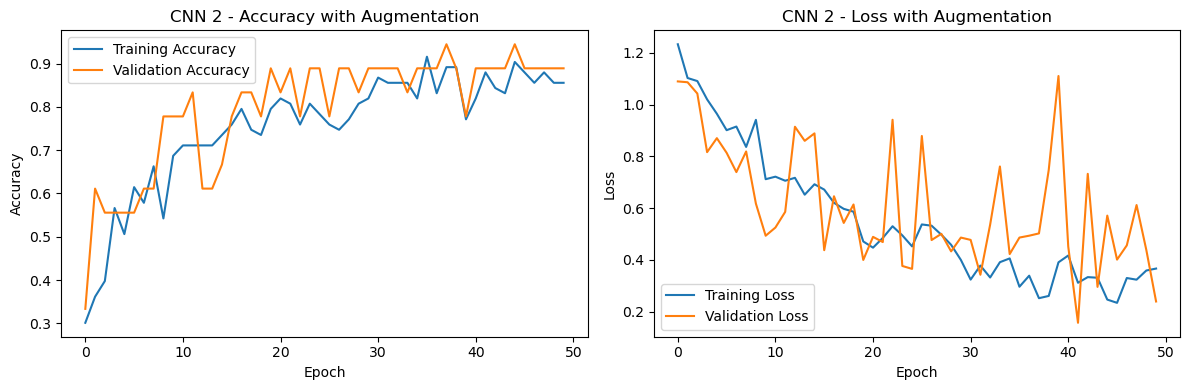

In [25]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_augmented.history["accuracy"], label="Training Accuracy")
plt.plot(history_augmented.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN 2 - Accuracy with Augmentation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_augmented.history["loss"], label="Training Loss")
plt.plot(history_augmented.history["val_loss"], label="Validation Loss")
plt.title("CNN 2 - Loss with Augmentation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

### 7.3 Compare validation results
Use validation accuracy and minimum validation loss to compare the experiments. Because the validation set is small, differences may be noisy.

In [26]:
basic_best_val_accuracy = max(history_basic.history["val_accuracy"])
aug_best_val_accuracy = max(history_augmented.history["val_accuracy"])

validation_comparison = pd.DataFrame({
    "CNN Model": ["CNN without augmentation", "CNN with augmentation"],
    "Best Validation Accuracy": [
        basic_best_val_accuracy,
        aug_best_val_accuracy
    ],
    "Minimum Validation Loss": [
        min(history_basic.history["val_loss"]),
        min(history_augmented.history["val_loss"])
    ]
})

print(validation_comparison)

print("\nValidation comparison interpretation: lower validation loss and stable validation accuracy are preferred. Use test metrics only for final reporting.")

                  CNN Model  Best Validation Accuracy  Minimum Validation Loss
0  CNN without augmentation                  0.777778                 0.616543
1     CNN with augmentation                  0.944444                 0.156562

Validation comparison interpretation: lower validation loss and stable validation accuracy are preferred. Use test metrics only for final reporting.


## 8. Validation-based model selection

Choose the preferred CNN using validation data before reviewing final test metrics. The test set is not used to select the model.

In [27]:
# Select using validation predictions only; the test set is not used for model selection.
val_prob_basic = cnn_basic.predict(X_val, verbose=0)
val_prob_aug = cnn_augmented.predict(X_val, verbose=0)
val_pred_basic = np.argmax(val_prob_basic, axis=1)
val_pred_aug = np.argmax(val_prob_aug, axis=1)

val_f1_basic = f1_score(y_val, val_pred_basic, average='macro', zero_division=0)
val_f1_aug = f1_score(y_val, val_pred_aug, average='macro', zero_division=0)
val_loss_basic = min(history_basic.history['val_loss'])
val_loss_aug = min(history_augmented.history['val_loss'])

validation_model_comparison = pd.DataFrame({
    'Model': ['CNN without augmentation', 'CNN with augmentation'],
    'Best Validation Accuracy': [max(history_basic.history['val_accuracy']), max(history_augmented.history['val_accuracy'])],
    'Validation Macro F1': [val_f1_basic, val_f1_aug],
    'Minimum Validation Loss': [val_loss_basic, val_loss_aug]
})
display(validation_model_comparison.round(4))

# Highest validation macro-F1 is primary; minimum validation loss breaks a tie.
if (val_f1_basic > val_f1_aug) or (np.isclose(val_f1_basic, val_f1_aug) and val_loss_basic <= val_loss_aug):
    best_model = cnn_basic
    best_model_name = 'CNN without augmentation'
else:
    best_model = cnn_augmented
    best_model_name = 'CNN with augmentation'

print('Selected model:', best_model_name)
print('Selection criterion: validation macro-F1; validation loss used as tie-breaker.')
print('The test set is reserved for final performance reporting.')


,Model,Best Validation Accuracy,Validation Macro F1,Minimum Validation Loss
0,CNN without augmentation,0.7778,0.7313,0.6165
1,CNN with augmentation,0.9444,0.8885,0.1566


Selected model: CNN with augmentation
Selection criterion: validation macro-F1; validation loss used as tie-breaker.
The test set is reserved for final performance reporting.


## 9. Model evaluation function
The function reports per-class precision, recall, F1-score, and confusion matrix, plus aggregate metrics. ROC-AUC is calculated as macro-averaged one-vs-rest multiclass ROC-AUC from predicted probabilities.

In [28]:
def evaluate_cnn(model, X_test, y_test, model_name):

    probabilities = model.predict(X_test, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    print("\n", model_name)
    print("-" * 50)

    print(classification_report(
        y_test,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=list(range(len(class_names)))
    )

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Disease")
    plt.ylabel("Actual Disease")
    plt.xticks(rotation=20)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # Multiclass ROC-AUC is defined only when every class is represented in y_test.
    try:
        roc_auc = roc_auc_score(
            y_test, probabilities, multi_class="ovr", average="macro",
            labels=np.arange(len(class_names))
        )
    except ValueError:
        roc_auc = np.nan
        print("ROC-AUC could not be calculated; check whether every class appears in the test set.")

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "Macro ROC-AUC (OvR)": roc_auc
    }

### 9.1 Evaluate both CNN experiments
This produces the comparison table and confusion matrices. Since the test set is small, treat the scores as preliminary estimates.


 CNN without augmentation
--------------------------------------------------
                       precision    recall  f1-score   support

Bacterial leaf blight       0.71      0.83      0.77         6
           Brown spot       0.50      0.33      0.40         6
            Leaf smut       0.57      0.67      0.62         6

             accuracy                           0.61        18
            macro avg       0.60      0.61      0.59        18
         weighted avg       0.60      0.61      0.59        18



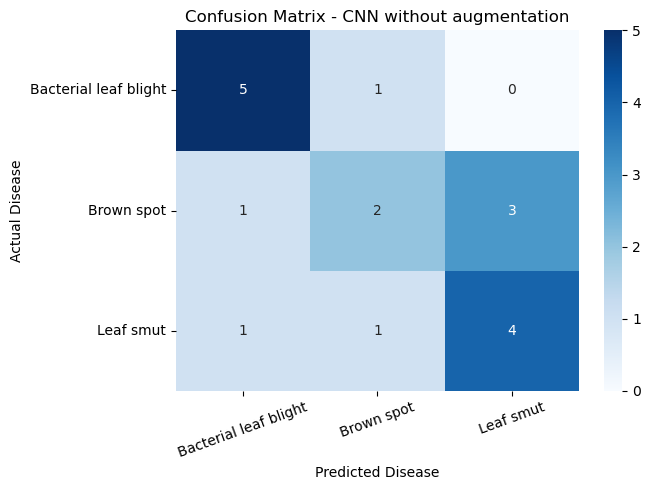


 CNN with augmentation
--------------------------------------------------
                       precision    recall  f1-score   support

Bacterial leaf blight       0.80      0.67      0.73         6
           Brown spot       0.67      0.67      0.67         6
            Leaf smut       0.71      0.83      0.77         6

             accuracy                           0.72        18
            macro avg       0.73      0.72      0.72        18
         weighted avg       0.73      0.72      0.72        18



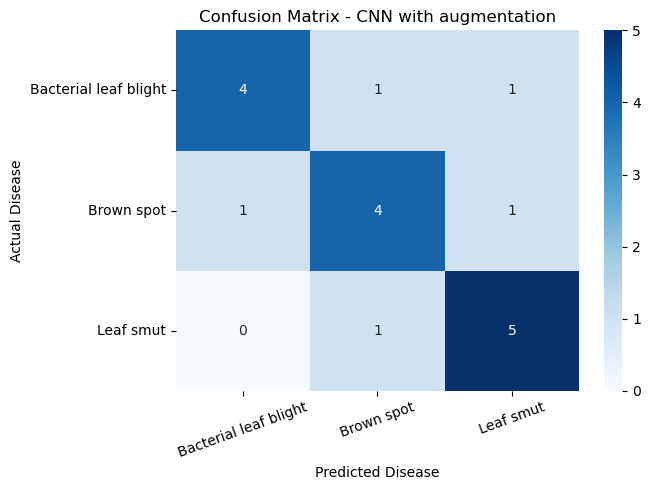


CNN Model Comparison:
                      Model  Accuracy  Macro Precision  Macro Recall  \
0  CNN without augmentation    0.6111           0.5952        0.6111   
1     CNN with augmentation    0.7222           0.7270        0.7222   

   Macro F1  Macro ROC-AUC (OvR)  
0    0.5949               0.7546  
1    0.7211               0.8935  


In [29]:
results = []

results.append(
    evaluate_cnn(
        cnn_basic, X_test, y_test,
        "CNN without augmentation"
    )
)

results.append(
    evaluate_cnn(
        cnn_augmented, X_test, y_test,
        "CNN with augmentation"
    )
)

results_df = pd.DataFrame(results)

print("\nCNN Model Comparison:")
print(results_df.round(4))

## 10. Save the Preferred CNN

The preferred CNN is selected using validation macro-F1.
Validation loss is used as a tie-breaker when needed.
The test set is kept separate and is used only for final evaluation.

### 10.1 Save the selected model
The `.keras` file stores the trained model. Keep a copy of the class order (`class_names`) with the model because prediction indices map to this list.

In [30]:
best_model.save("rice_leaf_disease_cnn.keras")

print("Selected CNN model saved successfully.")

Selected CNN model saved successfully.


### 10.2 Random Dataset Image Prediction Demo

This section selects a random image from the existing dataset and uses the trained CNN to predict its disease class. The displayed confidence is the model's output score, not its accuracy. Since the image may belong to the training, validation, or test set, this demonstration is not an independent evaluation of model performance.

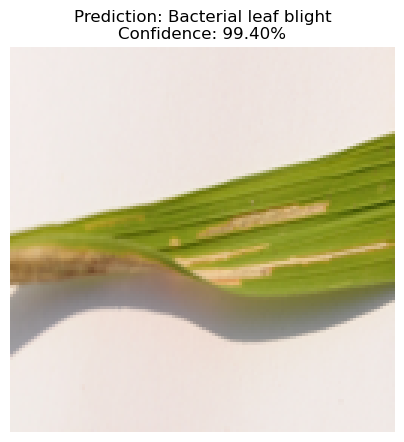

Random image: Data\Bacterial leaf blight\DSC_0381.JPG
Predicted disease: Bacterial leaf blight
Confidence: 99.40%


In [31]:
# Define the dataset folder
DATA_DIR = Path("Data")

# Find images from the three disease folders
class_names = [
    "Bacterial leaf blight",
    "Brown spot",
    "Leaf smut"
]

image_extensions = {".jpg", ".jpeg", ".png"}

image_files = []

for class_name in class_names:
    class_folder = DATA_DIR / class_name

    for image_path in class_folder.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in image_extensions:
            image_files.append(image_path)

# Select a random image
if len(image_files) == 0:
    print("No images found. Check the Data folder path.")
else:
    new_image_path = random.choice(image_files)

    image = Image.open(new_image_path).convert("RGB")
    image = image.resize(IMG_SIZE)

    image_array = np.array(image, dtype=np.float32) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    prediction = best_model.predict(image_array, verbose=0)
    predicted_index = int(np.argmax(prediction[0]))
    predicted_disease = class_names[predicted_index]
    confidence = float(prediction[0][predicted_index] * 100)

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(
        f"Prediction: {predicted_disease}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.axis("off")
    plt.show()

    print("Random image:", new_image_path)
    print("Predicted disease:", predicted_disease)
    print(f"Confidence: {confidence:.2f}%")

## 11. CNN model comparison chart
Compare all metrics side by side. Higher scores are generally better, but macro precision, recall, F1-score, ROC-AUC, confusion matrices, and validation stability should be considered together.

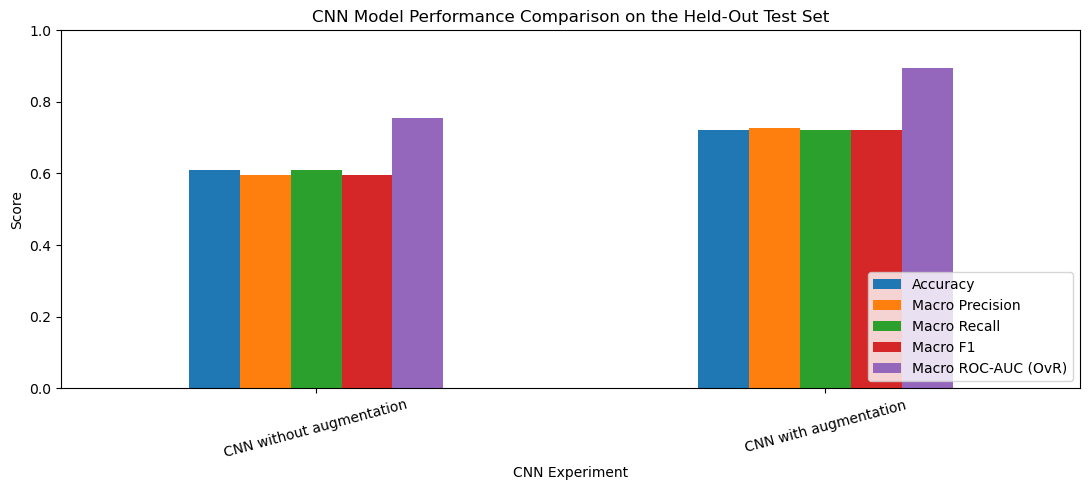

In [32]:
metrics = ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Macro ROC-AUC (OvR)']
comparison_plot = results_df.set_index('Model')[metrics]
comparison_plot.plot(kind='bar', figsize=(11, 5))
plt.title('CNN Model Performance Comparison on the Held-Out Test Set')
plt.ylabel('Score')
plt.xlabel('CNN Experiment')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 12. Model Comparison and Result Interpretation

The CNN with data augmentation performed better than the baseline CNN
on the recorded test split.

| Metric | Without Augmentation | With Augmentation |
|---|---:|---:|
| Test Accuracy | 61.11% | 72.22% |
| Macro Precision | 59.52% | 72.70% |
| Macro Recall | 61.11% | 72.22% |
| Macro F1-score | 59.49% | 72.11% |
| Macro ROC-AUC | 75.46% | 89.35% |

The test set contains only 18 images, with six images per class. Therefore, the reported performance metrics are preliminary and may vary considerably with a different data split. Further testing with a larger, independent dataset is needed before drawing conclusions about real-world performance.

In [33]:
print('Final test-set comparison:')
display(results_df.round(4))

if len(results_df) == 2:
    f1_values = results_df.set_index('Model')['Macro F1']
    print('Test-set macro-F1 difference is descriptive only; model selection was based on validation results.')
    print(f1_values.to_string())

print('Selected candidate based on validation:', best_model_name)

Final test-set comparison:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC (OvR)
0,CNN without augmentation,0.6111,0.5952,0.6111,0.5949,0.7546
1,CNN with augmentation,0.7222,0.7270,0.7222,0.7211,0.8935


Test-set macro-F1 difference is descriptive only; model selection was based on validation results.
Model
CNN without augmentation    0.594872
CNN with augmentation       0.721057
Selected candidate based on validation: CNN with augmentation


## 13. Challenges faced and techniques used

| Challenge | Technique used | Reason and limitation |
|---|---|---|
| Small dataset | Augmentation, dropout, early stopping | May reduce overfitting, but cannot replace more real images |
| Class-name mismatch | Inspect folder-derived labels and verify with instructor | Leaf smut must not be relabelled as Leaf blast |
| Unequal image dimensions | Resize to a fixed 128 × 128 input | Provides consistent CNN input dimensions; resizing can lose fine detail |
| Different color modes | Convert images to RGB | Ensures a consistent three-channel input |
| Potential corrupted files | Open and inspect every image | Unreadable files are excluded and should be reported |
| Exact duplicate files | SHA-256 content audit | Finds byte-identical files, but not near-duplicates |
| Overfitting | Dropout, early stopping, validation curves | Helps control training but performance estimates remain uncertain |
| Tiny test set | Stratified split and cautious interpretation | A few errors can change metrics substantially |
| Augmentation may distort symptoms | Visualize transformed examples and compare validation results | Only use transformations that preserve disease cues |

## 14. Recommendations for future improvement

1. Confirm whether the intended class is Leaf smut or Leaf blast and obtain correctly labelled images if necessary.
2. Collect substantially more images across farms, rice varieties, disease stages, devices, and lighting conditions.
3. Check for near-duplicate images and, where possible, split by plant or capture session to reduce leakage.
4. Repeat experiments with multiple stratified splits or cross-validation where class counts permit; report variability.
5. Tune image size, learning rate, CNN depth, dropout, and augmentation settings using validation data only.
6. Evaluate on an independent field dataset before any real-world use.
7. Treat softmax scores as model confidence outputs, not calibrated probabilities or expert diagnoses.

## 15. Conclusion

This project builds a CNN workflow for classifying the three disease labels present in the extracted dataset. It includes image-level EDA, data quality checks, preprocessing, stratified splitting, a baseline CNN, a CNN with training-only augmentation, and evaluation using accuracy, macro precision, macro recall, macro F1, ROC-AUC, and confusion matrices. The preferred model is chosen using validation macro-F1, with validation loss used as a tie-breaker, while the held-out test set is used for final reporting.

The final conclusion about whether augmentation helped must be based on the measured validation and test results produced by this notebook. Since the dataset is very small and its supplied class names may conflict with the assignment brief, the model should be considered an educational prototype. More labelled images, independent field validation, and confirmation of the correct disease classes are required before production use.